<a href="https://colab.research.google.com/github/NadiyaNowshin/Diabetes-Prediction-Model/blob/main/Diabetes_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Import Required Libraries

In [ ]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    classification_report,
    confusion_matrix
)

# Save model
import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


#Data Loading & Exploration

Load the Dataset

In [ ]:
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
df = pd.read_csv(url)

Display First Few Rows

In [ ]:
# Display the first five rows

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


Check Dataset Shape

In [ ]:
print("Dataset shape :" , df.shape)

Dataset shape : (768, 9)


Check Column Names

In [ ]:
print("Column Names:")
df.columns.to_list()

Column Names:


['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

Check Data Types

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Check Missing Values

In [ ]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Basic Statistics

In [ ]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


Check Duplicate Rows

In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


Check Target Distribution

In [ ]:
print(df["Outcome"].value_counts())

print("\nPercentage distribution:")
print(df["Outcome"].value_counts(normalize=True)*100)


Outcome
0    500
1    268
Name: count, dtype: int64

Percentage distribution:
Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


Visualize Target Distribution

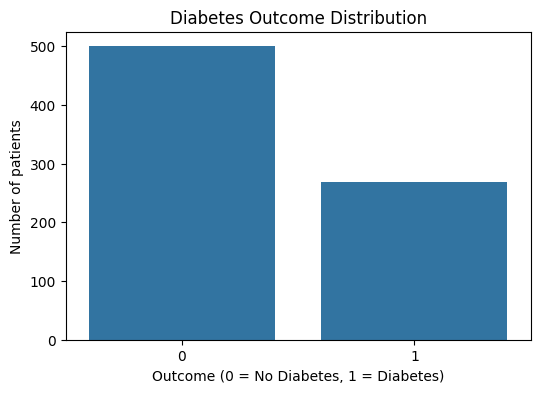

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x="Outcome", data=df)

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome (0 = No Diabetes, 1 = Diabetes)")
plt.ylabel("Number of patients")

plt.show()

#Data Preprocessing
Identify Invalid Zero Values

In [ ]:
zero_invalid_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

print((df[zero_invalid_columns] == 0).sum())

Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


Replace Invalid Zeros with NaN

In [ ]:
df_clean = df.copy()

df_clean[zero_invalid_columns] = df_clean[zero_invalid_columns].replace(0, np.nan)

print("Invalid zero values replaced with NaN.")

Invalid zero values replaced with NaN.


Check Missing Values After Replacement

In [ ]:
print("Missing values:", df_clean.isnull().sum())

Missing values: Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
df_clean[zero_invalid_columns] = df_clean[zero_invalid_columns].fillna(df_clean[zero_invalid_columns].median())

print("Missing values filled using median values.")

Missing values filled using median values.


Verify Missing Values

In [ ]:
print(df_clean.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


Separate Features and Target

In [ ]:
X = df_clean.drop("Outcome", axis =1)
y = df_clean["Outcome"]

print("Fetaure shape :", X.shape)
print("Target shape :", y.shape)

Fetaure shape : (768, 8)
Target shape : (768,)


Train/Test Split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=42,
    test_size=0.20,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (614, 8)
Testing set: (154, 8)


#Feature Scaling

Logistic Regression benefits from feature scaling.

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")


Feature scaling completed.


#Model 1: Logistic Regression
Train Logistic Regression

In [ ]:
logistic_model = LogisticRegression(
    max_iter = 1000,
    random_state = 42
)

logistic_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred_lr = logistic_model.predict(X_test_scaled)

# Get probability predictions for ROC-AUC
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:,1]


#Model 2: Random Forest

Train Random Forest

In [ ]:
random_forest_model = RandomForestClassifier(
    n_estimators = 200,
    random_state = 42
)

random_forest_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred_rf = random_forest_model.predict(X_test)

# Get probability predictions for ROC-AUC
y_prob_rf = random_forest_model.predict_proba(X_test)[:,1]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Evaluate Models


In [ ]:
model_results = {
    "Logistic Regression" : (y_pred_lr, y_prob_lr),
    "Random Forest" : (y_pred_rf, y_prob_rf)
}

results = []

print("Model Performance")
print("--------------------------------")

for model_name, (predictions, probability) in model_results.items():

    results.append({
      "Model" : model_name,
      "Accuracy" : accuracy_score(y_test, predictions),
      "Precision" :  precision_score(y_test, predictions),
      "Recall" : recall_score(y_test, predictions),
      "F1-score" : f1_score(y_test, predictions),
      "ROC-AUC" : roc_auc_score(y_test, probability)

     })

results_df = pd.DataFrame(results)

display(results_df)

Model Performance
--------------------------------


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.707792,0.600000,0.5,0.545455,0.812963
1,Random Forest,0.350649,0.350649,1.0,0.519231,0.429630


Classification Report

In [ ]:
print("Classification Report")
print("--------------------------------")

for model_name, (predictions, probability) in model_results.items():

    print("\n", model_name)
    print(classification_report(
        y_test,
        predictions))


Classification Report
--------------------------------

 Logistic Regression
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154


 Random Forest
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       100
           1       0.35      1.00      0.52        54

    accuracy                           0.35       154
   macro avg       0.18      0.50      0.26       154
weighted avg       0.12      0.35      0.18       154



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Confusion Matrix

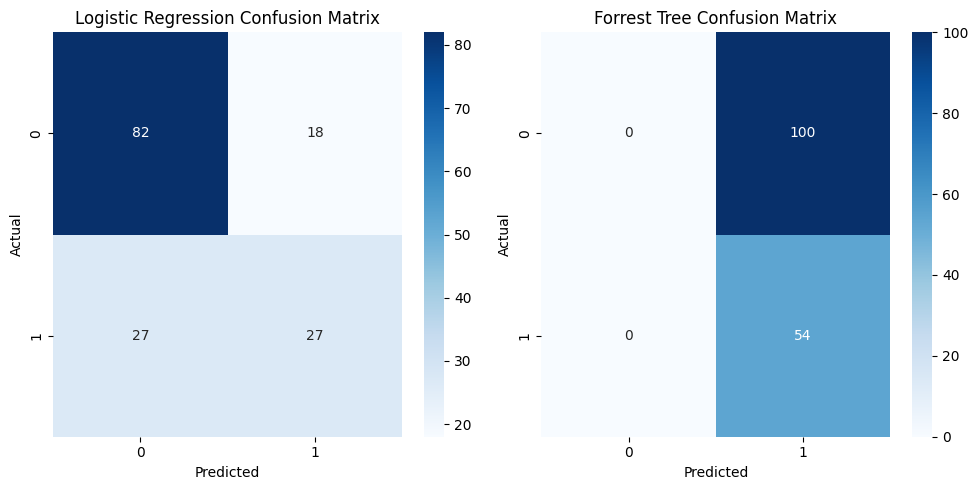

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10,5))

predictions = [
    ("Logistic Regression", y_pred_lr),
    ("Forrest Tree", y_pred_rf)
]

for ax, (name, prediction) in zip (axes, predictions):

    cm = confusion_matrix(y_test, prediction)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        ax=ax
     )

    ax.set_title(f"{name} Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

Plot ROC Curves

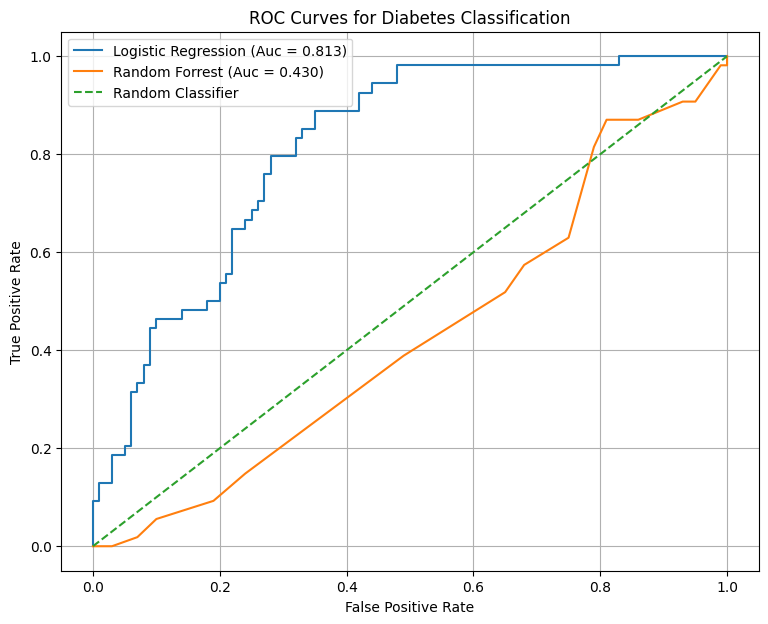

In [ ]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)

auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_rf = roc_auc_score(y_test, y_prob_rf)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr_lr,
    tpr_lr,
    label = f"Logistic Regression (Auc = {auc_lr:.3f})"
)


plt.plot(
    fpr_rf,
    tpr_rf,
    label = f"Random Forrest (Auc = {auc_rf:.3f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    label = "Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves for Diabetes Classification")
plt.legend()
plt.grid()
plt.show()


Visual Model Comparison

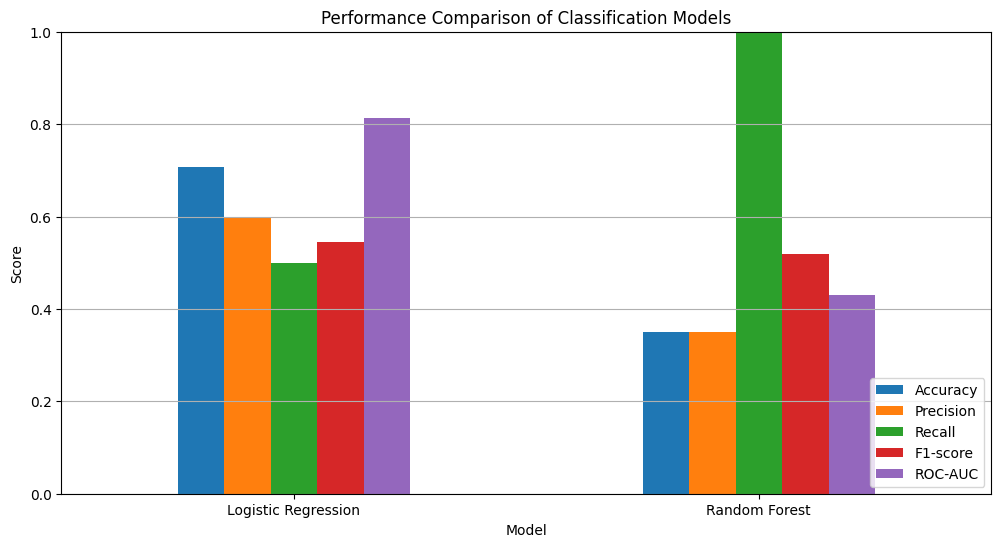

In [ ]:
results_df.set_index("Model")[[
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC"
]].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y")
plt.show()

Compare ROC-AUC scores

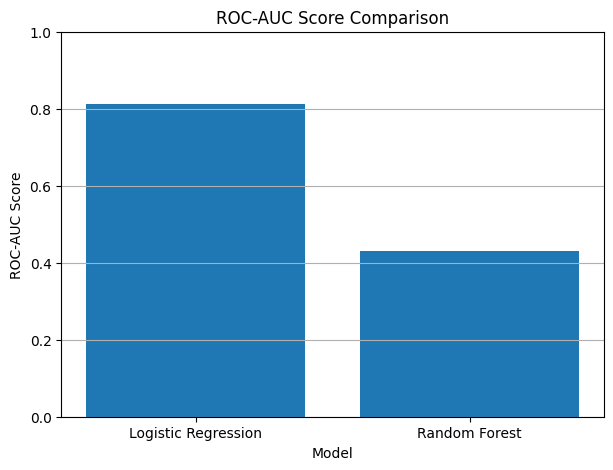

In [ ]:
plt.figure(figsize=(7, 5))

plt.bar(
    results_df["Model"],
    results_df["ROC-AUC"]
)

plt.title("ROC-AUC Score Comparison")
plt.xlabel("Model")
plt.ylabel("ROC-AUC Score")
plt.ylim(0, 1)

plt.xticks(rotation=0)

plt.grid(axis="y")

plt.show()

# Select the model with the highest ROC-AUC score

In [ ]:
best_row = results_df.loc[results_df["ROC-AUC"].idxmax()]

best_model_name = best_row["Model"]
best_roc_auc = best_row["ROC-AUC"]

if best_model_name == "Logistic Regression":
    best_model = logistic_model
else:
    best_model = random_forest_model

print("Best Model:", best_model_name)
print(f"ROC-AUC Score: {best_roc_auc:.4f}")

Best Model: Logistic Regression
ROC-AUC Score: 0.8130


Save the best model using Joblib

In [ ]:
import joblib

# Save the best model
joblib.dump(best_model, "best_diabetes_model.pkl")

print("Best Model:", best_model_name)
print(f"ROC-AUC Score: {best_roc_auc:.4f}")
print("Model saved successfully as 'best_diabetes_model.pkl'")

Best Model: Logistic Regression
ROC-AUC Score: 0.8130
Model saved successfully as 'best_diabetes_model.pkl'


Download Model

In [ ]:
from google.colab import files

files.download("best_diabetes_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Save the Scaler

In [ ]:
joblib.dump(scaler, "diabetes_scaler.pkl")

print("Scaler saved successfully as 'diabetes_scaler.pkl'")

Scaler saved successfully as 'diabetes_scaler.pkl'
